# Make your own test set, and have fun

This notebook shows how to

1. **generate** random circuits with the number of inputs, outputs, depth and gates you choose;
2. get their **truth tables**;
3. **re-synthesize** them with the trained model, alone and inside the XOR refinement loop;
4. build a **test set** along an axis of your choice and measure the model on it;
5. **plug in your own synthesizer** (a looped Transformer, a different encoder, a search
   procedure, ...) and compare.

The generator in `llrg/generate.py` is a small toy written for this release. It is **not** the
generator that built the paper's training and test corpora, so its circuits come from a
different distribution and the numbers below will not match the paper's tables.

Sizes use the paper's convention: every gate (AND or OR with 2 to 4 operands, two-operand
XOR, NOT) counts as one gate, and depth counts gates on the longest input-to-output path.

In [1]:
import sys, json
sys.path.insert(0, '..')   # run from notebooks/: make the llrg package importable
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from llrg import CircuitSynthesizer, circuit as C, harness as H, generate as G
from llrg.vocab import tokenize
from llrg.viz import show_tables
from transformers.utils import logging
logging.set_verbosity_error()   # silence a generation warning from transformers

model = CircuitSynthesizer.from_pretrained('../weights')   # CPU by default
print(f'{sum(p.numel() for p in model.parameters()):,} parameters')

2,203,136 parameters


## 1. Generate a circuit with a given depth and number of gates

`G.random_circuit(n, m, depth, gates, seed)` draws a random circuit with `n` inputs and `m`
outputs. Every output has exactly the requested depth, and the total number of gates is exactly
`gates` (leave it out to get a random size). The trained model reads tables with up to 5 inputs
and 5 outputs; the generator itself works for any `n`.

y0 = ((x1 XOR (x1 XOR x2)) AND NOT (x3 OR x1 OR x2) AND NOT x2 AND (x3 XOR x0)) XOR NOT (((x0 OR (x3 AND x1)) XOR x3) XOR x2)
y1 = NOT (NOT ((x2 OR x3 OR (x0 XOR x1)) XOR x3) AND (x2 XOR x0))
gates: 20  depth: 6


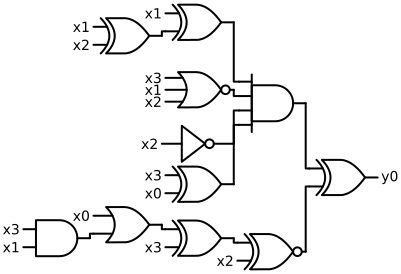

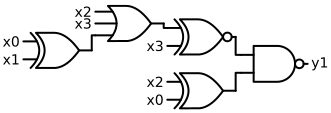

In [2]:
outs = G.random_circuit(n=4, m=2, depth=6, gates=20, seed=0)
for j, o in enumerate(outs):
    print(f'y{j} = {C.pretty(o)}')
print('gates:', G.size(outs), ' depth:', G.circuit_depth(outs))
for d in C.draw(outs):
    display(d)

## 2. Its truth table

The truth table lists the circuit's output on every input. It is all the model sees.

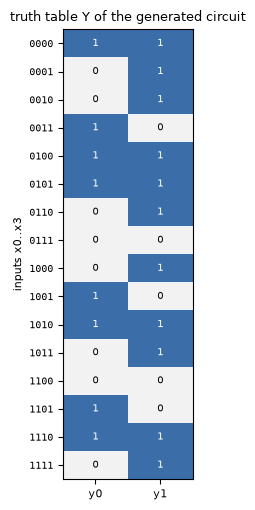

In [3]:
n, m = 4, 2
Y = C.evaluate(outs, n)
show_tables([Y], ['truth table Y of the generated circuit'], n)

## 3. Re-synthesize it

The model was trained on circuits of depth at most 2, so on this depth-6 circuit a single
forward pass usually makes some errors. XOR refinement calls the same model on the cells that
are still wrong and XORs the corrections together; the result is always exact.

In [4]:
one, pred, _ = H.one_shot(model, Y)
if pred is None:
    print('single pass: unparsable output')
else:
    print(f'single pass: {int((pred != Y).sum())} of {Y.size} cells wrong')

res = H.xor_refine(model, Y, verbose=True)
syn = res['outputs']
assert (C.evaluate(syn, n) == Y).all()
print()
for j, o in enumerate(syn):
    print(f'y{j} = {C.pretty(o)}')
print(f"original:      {G.size(outs):3d} gates, depth {G.circuit_depth(outs)}")
print(f"re-synthesized: {G.size(syn):3d} gates, depth {G.circuit_depth(syn)}  ({res['steps']} model calls accepted)")

single pass: 7 of 32 cells wrong
step 1 (direct): 7 wrong cells left


step 2 (direct): 3 wrong cells left
step 3 (direct): 0 wrong cells left

y0 = (x0 XOR x2) XOR NOT x3 XOR (x1 AND x3 AND NOT x0)
y1 = (x0 AND x2) XOR NOT x3 XOR ((x0 OR x1 OR x2 OR x3) AND (x0 XOR x3) AND (x1 OR x2 OR x3) AND (x1 XOR x3)) XOR ((x0 XOR x3) AND (x1 XOR x2) AND (x2 OR x3))
original:       20 gates, depth 6
re-synthesized:  15 gates, depth 3  (3 model calls accepted)


The re-synthesized circuit computes the same function. It is often shallower than the circuit
we started from: it is an XOR of a few depth-2 circuits, whatever the depth of the original.

## 4. A test set along an axis of your choice

`G.test_set(n, m, depth, count, gates)` returns `count` circuits with distinct truth tables.
Here we sweep the depth at `(n, m) = (4, 4)` and measure, for each depth, the single-pass error
(fraction of wrong cells), the number of accepted refinement steps, and the size and depth of
the output. Change the sweep to explore other axes: number of gates at fixed depth, number of
inputs or outputs, and so on.

In [5]:
depths = [2, 4, 6, 8, 10]
per_depth = 20
rows = []
for q in depths:
    tests = G.test_set(n=4, m=4, depth=q, count=per_depth, seed=q)
    err, steps, gates, dep = [], [], [], []
    for t in tests:
        Yt = np.array(t['truth_table'], dtype=np.uint8)
        _, p, _ = H.one_shot(model, Yt)
        err.append(1.0 if p is None else float((p != Yt).mean()))
        r = H.xor_refine(model, Yt)
        steps.append(r['steps']); gates.append(G.size(r['outputs'])); dep.append(G.circuit_depth(r['outputs']))
    rows.append((q, 100 * np.mean(err), np.mean(steps), np.mean(gates), np.mean(dep)))
    print(f'depth {q:2d}: single-pass error {rows[-1][1]:5.2f}%   steps {rows[-1][2]:.2f}   '
          f'output {rows[-1][3]:5.1f} gates, depth {rows[-1][4]:.2f}')

depth  2: single-pass error  0.78%   steps 1.15   output   9.2 gates, depth 2.30


depth  4: single-pass error  3.83%   steps 2.00   output  13.1 gates, depth 3.15


depth  6: single-pass error  8.67%   steps 2.45   output  16.0 gates, depth 3.15


depth  8: single-pass error  8.44%   steps 2.60   output  15.7 gates, depth 3.30


depth 10: single-pass error  8.52%   steps 2.60   output  17.1 gates, depth 3.05


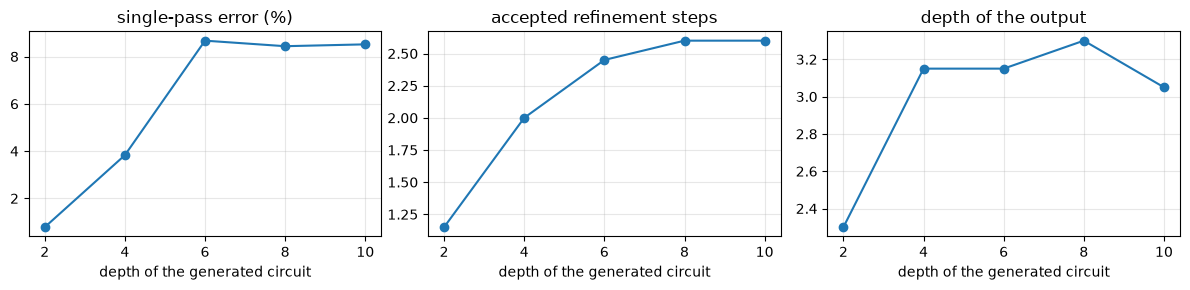

In [6]:
q, e, s, g, d = map(np.array, zip(*rows))
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].plot(q, e, 'o-'); ax[0].set_title('single-pass error (%)')
ax[1].plot(q, s, 'o-'); ax[1].set_title('accepted refinement steps')
ax[2].plot(q, d, 'o-'); ax[2].set_title('depth of the output')
for a in ax:
    a.set_xlabel('depth of the generated circuit'); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Two caveats if you compare with the paper. The paper's test sets were drawn by a different
generator and **decontaminated**: every truth table that also occurs in the training corpus was
removed. The training corpus is not released, so these test sets are not decontaminated;
shallow tables in particular may have been seen in training. And the paper reports 1,000
circuits per depth; use more than 20 for stable numbers.

### Save and share a test set

A test set is plain JSON, so you can store it, share it, and load it back.

In [7]:
tests = G.test_set(n=4, m=4, depth=8, count=100, seed=0)
with open('my_test_set.json', 'w') as f:
    json.dump(tests, f)
loaded = json.load(open('my_test_set.json'))
print(len(loaded), 'circuits; first one:')
print(loaded[0]['circuit'])

100 circuits; first one:
~ ( ( ~ ( ( 2 ⊻ ( ( 0 ∧ 3 ∧ 1 ∧ 2 ) ⊻ 3 ) ) ∧ 2 ) ⊻ ( 2 ∨ 3 ) ) ⊻ 2 )
~ ( ~ ( 2 ∧ ( ( 1 ⊻ ( 3 ⊻ ~ 0 ) ) ⊻ 2 ) ) ⊻ ( 2 ∧ ( 3 ∧ 0 ∧ ( 1 ⊻ 3 ) ) ) )
~ ( 2 ⊻ ~ ( 0 ∨ ( 0 ⊻ ~ ( ( 2 ∨ 1 ) ⊻ 1 ) ) ) )
( 1 ∧ ~ ( ~ ( 0 ∨ ~ ( 0 ⊻ 2 ) ∨ 1 ) ∧ 2 ) ) ∨ ( 1 ∧ ( 1 ∧ 3 ∧ 2 ) )


## 5. Plug in your own synthesizer

The refinement loop only needs an object with a method `synthesize(Y)` that returns a circuit as
a list of token ids (`llrg.vocab.tokenize` turns a circuit string into ids). Whatever it returns,
the loop keeps a step only if it reduces the number of wrong cells, and writes out what remains
exactly, so the final circuit is always correct; a better synthesizer makes it smaller and needs
fewer steps.

Below, a deliberately weak synthesizer: for each output, it writes the sum of products of only
the first half of the rows where the output is 1. On its own it is never exact; in the loop it is.

In [8]:
class HalfSOP:
    """A weak synthesizer: covers only half of the 1-cells of each output."""
    def synthesize(self, Y):
        n = int(np.log2(Y.shape[0]))
        outs = []
        for j in range(Y.shape[1]):
            col = Y[:, j].copy()
            ones = np.flatnonzero(col)
            col[ones[len(ones) // 2 + (len(ones) % 2):]] = 0   # drop the second half
            outs.append(C.sop(col, n))
        return tokenize(C.circuit_to_string(outs))

mine = HalfSOP()
_, p, _ = H.one_shot(mine, Y)
print(f'HalfSOP alone: {int((p != Y).sum())} of {Y.size} cells wrong')
r = H.xor_refine(mine, Y)
assert (C.evaluate(r['outputs'], n) == Y).all()
print(f"HalfSOP in the loop: exact after {r['steps']} steps, {G.size(r['outputs'])} gates, "
      f"depth {G.circuit_depth(r['outputs'])}")
print(f"trained model in the loop: {G.size(syn)} gates, depth {G.circuit_depth(syn)}")

HalfSOP alone: 9 of 32 cells wrong
HalfSOP in the loop: exact after 4 steps, 24 gates, depth 4
trained model in the loop: 15 gates, depth 3


Replace `HalfSOP` with your own model and rerun section 4 with it. Some directions:

- **Architectures** that may extrapolate in depth on their own: looped or recurrent
  Transformers, models with adaptive computation, graph networks over the circuit.
- **Better loops**: smarter masks for the retry step, or choosing which outputs to correct first.
- **More inputs**: the paper's projection loop (Algorithm 2) handles more than 5 inputs by
  synthesizing sub-tables on 5 of them; it is described in the paper.
- **Other axes**: gates at fixed depth, structured families (adders, multiplexers, parity), or
  circuits from real designs.

The quantities to beat are the single-pass error, the number of model calls, and the size and
depth of the exact output.